# Step.1:- Get the data
## 1. Download the data set from websites(kaggle dataset)
## 2. import all dependencies of your project
## 3. load your project

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('pima-data.xlsx')
df

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,has_diabetes,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,1.8912,False,False
764,2,122,70,27,0,36.8,0.340,27,0,1.0638,False,False
765,5,121,72,23,112,26.2,0.245,30,0,0.9062,False,False
766,1,126,60,0,0,30.1,0.349,47,1,0.0000,True,True


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_preg       768 non-null    int64  
 1   glucose_conc   768 non-null    int64  
 2   diastolic_bp   768 non-null    int64  
 3   thickness      768 non-null    int64  
 4   insulin        768 non-null    int64  
 5   bmi            768 non-null    float64
 6   diab_pred      768 non-null    float64
 7   age            768 non-null    int64  
 8   diabetes_orig  768 non-null    int64  
 9   skin           768 non-null    float64
 10  has_diabetes   768 non-null    bool   
 11  diabetes       768 non-null    bool   
dtypes: bool(2), float64(3), int64(7)
memory usage: 61.6 KB


# Step 2:- Cleaning the dataset
## 1. check the null value is present in your dataset or not

In [4]:
df.isnull().sum()

num_preg         0
glucose_conc     0
diastolic_bp     0
thickness        0
insulin          0
bmi              0
diab_pred        0
age              0
diabetes_orig    0
skin             0
has_diabetes     0
diabetes         0
dtype: int64

## 2. check the correlation of your project

In [5]:
df.corr()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,has_diabetes,diabetes
num_preg,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898,-0.081672,0.221898,0.221898
glucose_conc,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581,0.057328,0.466581,0.466581
diastolic_bp,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068,0.207371,0.065068,0.065068
thickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752,1.000000,0.074752,0.074752
insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548,0.436783,0.130548,0.130548
bmi,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695,0.392573,0.292695,0.292695
diab_pred,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844,0.183928,0.173844,0.173844
age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356,-0.113970,0.238356,0.238356
diabetes_orig,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000,0.074752,1.000000,1.000000
skin,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752,1.000000,0.074752,0.074752


In [6]:
def check_corr(size):
    corr = df.corr()
    fig,ax=plt.subplots(figsize = (size,size))
    cmap = 'plasma'
    ax.matshow(corr,cmap = cmap)
    plt.xticks(range(len(corr.columns)),corr.columns,rotation = 90)
    plt.yticks(range(len(corr.columns)),corr.columns)
    plt.show()

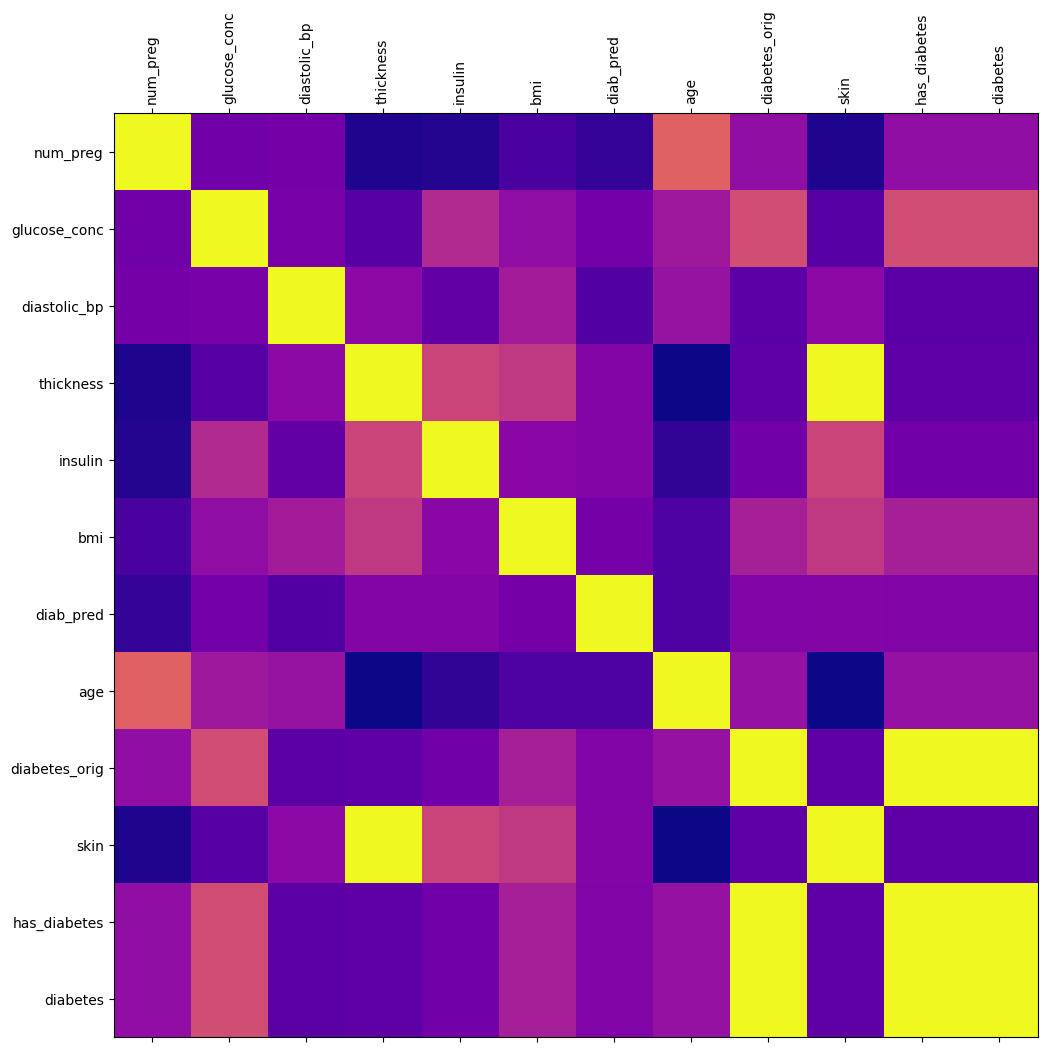

In [7]:
check_corr(12)

## we observed few columns are correlated to each other
## 1. skin and thickness are correlated to each other
## 2. has_diabetes and diabetes_orig are correlated to each other
## 3. diabetes and diabetes_orig are correlated to each other
## 4. has_diabetes and diabetes are correalated to each othet

# drop the correlated colmns

In [8]:
df.drop('thickness',axis=1,inplace=True)
df.drop('diabetes_orig',axis=1,inplace=True)
df.drop('has_diabetes',axis=1,inplace=True)

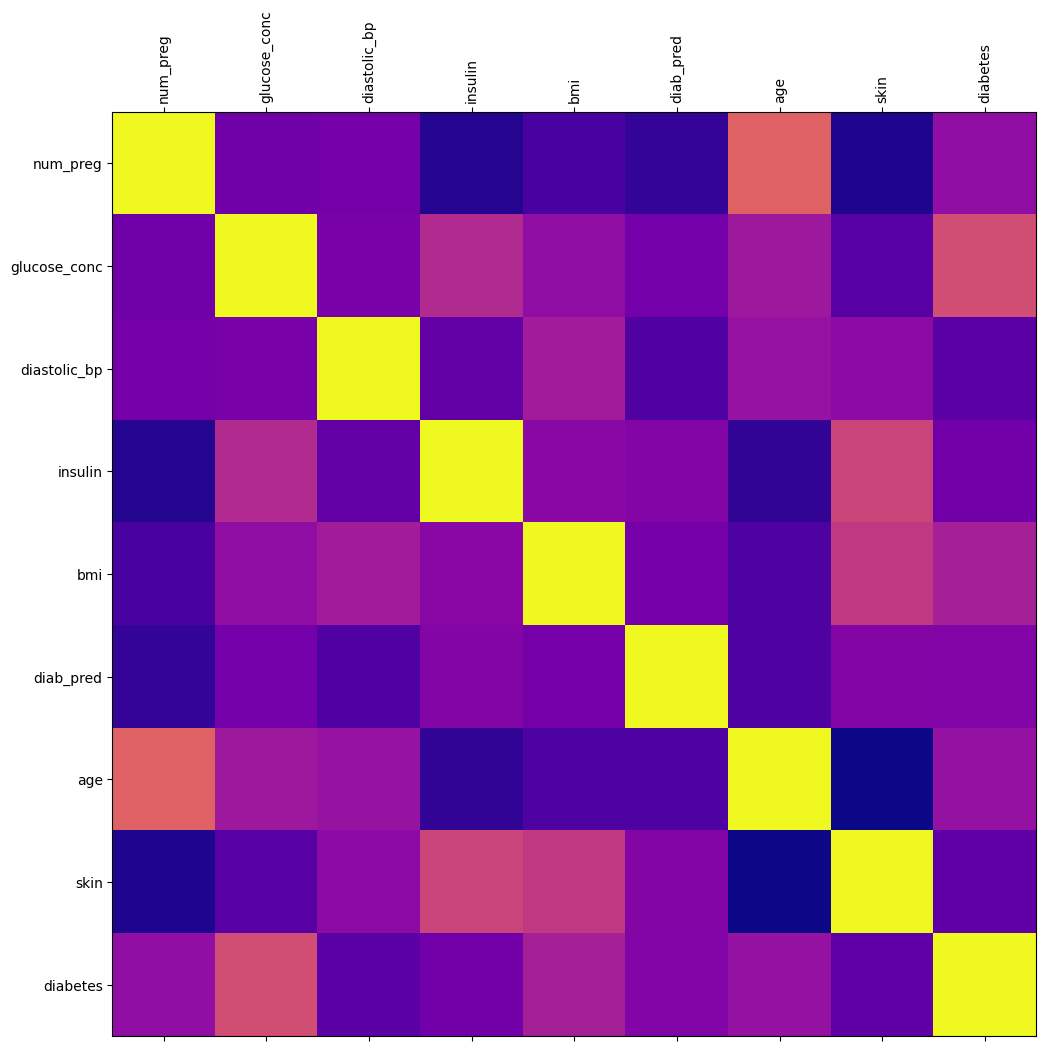

In [9]:
check_corr(12)

## 3. convert string to integer type data

In [10]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,True
1,1,85,66,0,26.6,0.351,31,1.1426,False
2,8,183,64,0,23.3,0.672,32,0.0000,True
3,1,89,66,94,28.1,0.167,21,0.9062,False
4,0,137,40,168,43.1,2.288,33,1.3790,True


In [11]:
df['diabetes'].unique()

array([ True, False])

In [12]:
df['diabetes']=df['diabetes'].map({True:1,False:0})

In [13]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1


## 4. check the propertion of data

In [14]:
num_true = len(df.loc[df['diabetes']==1])
num_false = len(df.loc[df['diabetes']==0])
print(num_true)
print(num_false)

268
500


In [15]:
true_percentage = ((num_true / (num_true + num_false)) * 100)
false_percentage = ((num_false / (num_true + num_false)) * 100)
print(true_percentage)
print(false_percentage)


34.89583333333333
65.10416666666666


# 5. how to handle imbalanced data ?
## using sampling techiques
# 1. under sampling
## a) it is a techinque used to balance imbalanced dataset by decreading th size of the majority data set to minority dataset
## b) under sampling is not prefere
# 2. over sampling
## 
# 3. SMOTE techique

# Step 3:-Train the model

## 1. train test split

In [16]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi',
       'diab_pred', 'age', 'skin', 'diabetes'],
      dtype='object')

In [17]:
input_columns =['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi','diab_pred', 'age', 'skin' ]
output_columns = ['diabetes']

x = df[input_columns].values
y = df[output_columns].values



In [18]:
print(x)

[[  6.     148.      72.     ...   0.627   50.       1.379 ]
 [  1.      85.      66.     ...   0.351   31.       1.1426]
 [  8.     183.      64.     ...   0.672   32.       0.    ]
 ...
 [  5.     121.      72.     ...   0.245   30.       0.9062]
 [  1.     126.      60.     ...   0.349   47.       0.    ]
 [  1.      93.      70.     ...   0.315   23.       1.2214]]


In [19]:
print(y)

[[1]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]


In [20]:
from sklearn.model_selection import train_test_split

In [21]:
#pip install scikit-learn

In [22]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.3,random_state = 42)

In [23]:
# a,b,c,d = 10,20,30,40
# print(d)

In [24]:
# d,b,c,a = 10,20,30,40
# print(d)

In [25]:
# x1 = [1,2,3,4,5,6,7,8,9,10]
# y1 = ['A','A','A','A','A','B','B','B','B','B']
# x_train,x_test,y_train,y_test = train_test_split(x1,y1,test_size = 0.3,random_state = 42)
# print(x_train)
# print(x_test)
# print(y_train)
# print(y_test)

In [26]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(537, 8)
(231, 8)
(537, 1)
(231, 1)


In [27]:
# x2 = 10
# y2 = 20

# print(f" sum of {x2} and {y2} is {x2 +y2}")
# print("sum of {} and {} is {}".format(x2, y2, x2 + y2))

## check the propertion of training and testing percenteage

In [28]:
print('{0:0.2f}% in the training set'.format((len(x_train)/len(df.index))*100))


print('{0:0.2f}% in the testing set'.format((len(x_test)/len(df.index))*100))

69.92% in the training set
30.08% in the testing set


In [29]:
print('training true:{0} ({1:0.2f}%)'.format(len(y_train[y_train[ : ] == 1]), (len(y_train[y_train[ : ] == 1])/len(y_train)*100)))

print('training flase:{0} ({1:0.2f}%)'.format(len(y_train[y_train[ : ] == 0]), (len(y_train[y_train[ : ] == 0])/len(y_train)*100)))

print('test true:{0} ({1:0.2f}%)'.format(len(y_test[y_test[ : ] == 1]), (len(y_test[y_test[ : ] == 1])/len(y_test)*100)))

print('test true:{0} ({1:0.2f}%)'.format(len(y_test[y_test[ : ] == 0]), (len(y_test[y_test[ : ] == 0])/len(y_test)*100)))

training true:188 (35.01%)
training flase:349 (64.99%)
test true:80 (34.63%)
test true:151 (65.37%)


## post split preparation

In [30]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi',
       'diab_pred', 'age', 'skin', 'diabetes'],
      dtype='object')

In [31]:
total_num_preg = len(df.loc[df['num_preg'] == 0])
print(f'number of Rows missing in num_preg column is {total_num_preg}')

total_glucose_conc = len(df.loc[df['glucose_conc'] == 0])
print(f'number of Rows missing in glucose_conc column is {total_glucose_conc}')


total_diastolic_bp = len(df.loc[df['diastolic_bp'] == 0])
print(f'number of Rows missing in diastolic_bp column is {total_diastolic_bp}')


total_insulin = len(df.loc[df['insulin'] == 0])
print(f'number of Rows missing in insulin column is {total_insulin}')

total_bmi = len(df.loc[df['bmi'] == 0])
print(f'number of Rows missing in bmi column is {total_bmi}')

total_diab_pred = len(df.loc[df['diab_pred'] == 0])
print(f'number of Rows missing in diab_pred column is {total_diab_pred}')

total_age = len(df.loc[df['age'] == 0])
print(f'number of Rows missing in age column is {total_age}')

total_skin = len(df.loc[df['skin'] == 0])
print(f'number of Rows missing in skin column is {total_skin}')

total_diabetes = len(df.loc[df['diabetes'] == 0])
print(f'number of Rows missing in diabetes column is {total_diabetes}')



number of Rows missing in num_preg column is 111
number of Rows missing in glucose_conc column is 5
number of Rows missing in diastolic_bp column is 35
number of Rows missing in insulin column is 374
number of Rows missing in bmi column is 11
number of Rows missing in diab_pred column is 0
number of Rows missing in age column is 0
number of Rows missing in skin column is 227
number of Rows missing in diabetes column is 500


In [32]:
from sklearn.impute import SimpleImputer

In [33]:
# fill_zeros = SimpleImputer(missing_values=0,strategy='mean')
# x_train = fill_zeros.fit_transform(x_train)
# x_test = fill_zeros.fit_transform(x_test)

In [34]:
fill_zeros = SimpleImputer(missing_values=0,strategy='mean')
x_train = fill_zeros.fit_transform(x_train)
x_test = fill_zeros.transform(x_test)

In [35]:
x_train[0:5]

array([[1.00000000e+00, 9.50000000e+01, 6.00000000e+01, 5.80000000e+01,
        2.39000000e+01, 2.60000000e-01, 2.20000000e+01, 7.09200000e-01],
       [5.00000000e+00, 1.05000000e+02, 7.20000000e+01, 3.25000000e+02,
        3.69000000e+01, 1.59000000e-01, 2.80000000e+01, 1.14260000e+00],
       [4.34056399e+00, 1.35000000e+02, 6.80000000e+01, 2.50000000e+02,
        4.23000000e+01, 3.65000000e-01, 2.40000000e+01, 1.65480000e+00],
       [4.00000000e+00, 1.31000000e+02, 6.80000000e+01, 1.66000000e+02,
        3.31000000e+01, 1.60000000e-01, 2.80000000e+01, 8.27400000e-01],
       [1.00000000e+00, 1.03000000e+02, 3.00000000e+01, 8.30000000e+01,
        4.33000000e+01, 1.83000000e-01, 3.30000000e+01, 1.49720000e+00]])

# e.standardize the data
## it is a data processing techinique which is used to make all values into single scale i.e mean is 0 and sd is 1

In [37]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [38]:
x_train [0:5]

array([[-1.15687814e+00, -8.96200501e-01, -1.00392807e+00,
        -1.14563966e+00, -1.20379368e+00, -6.14216360e-01,
        -9.48610283e-01, -1.25782829e+00],
       [ 2.28370750e-01, -5.64089421e-01, -1.97904130e-02,
         1.99702256e+00,  6.64529988e-01, -9.09737865e-01,
        -4.34666726e-01,  4.16397301e-02],
       [ 6.15174086e-16,  4.32243819e-01, -3.47836300e-01,
         1.11425228e+00,  1.44060290e+00, -3.06991033e-01,
        -7.77295764e-01,  1.57737467e+00],
       [-1.17941473e-01,  2.99399387e-01, -3.47836300e-01,
         1.25549552e-01,  1.18404607e-01, -9.06811910e-01,
        -4.34666726e-01, -9.03427923e-01],
       [-1.15687814e+00, -6.30511637e-01, -3.46427222e+00,
        -8.51382901e-01,  1.58432010e+00, -8.39514933e-01,
        -6.38042901e-03,  1.10484084e+00]])

## train the model using naivebayees algorithm

In [39]:
from sklearn.naive_bayes import GaussianNB

In [41]:
nb_model = GaussianNB()
nb_model.fit(x_train,y_train.ravel()) ## learning from the data or train the data

,priors,None
,var_smoothing,1e-09


In [42]:
from sklearn import metrics
nb_predict_train = nb_model.predict(x_train)
print(f" predicted accuracy of naive bayees model is {metrics.accuracy_score(y_train,nb_predict_train)}")

 predicted accuracy of naive bayees model is 0.7541899441340782


In [43]:
nb_predict_test = nb_model.predict(x_test)
print(f" predicted testing accuracy of naive bayees model is {metrics.accuracy_score(y_test,nb_predict_test)}")

 predicted testing accuracy of naive bayees model is 0.7402597402597403


# step-4: Testing using confusion matrix

In [44]:
print('confusion matrix')
print("{}".format(metrics.confusion_matrix(y_test,nb_predict_test)))

confusion matrix
[[119  32]
 [ 28  52]]


## classification report

In [45]:
print('classification report')
print("{}".format(metrics.classification_report(y_test,nb_predict_test)))

classification report
              precision    recall  f1-score   support

           0       0.81      0.79      0.80       151
           1       0.62      0.65      0.63        80

    accuracy                           0.74       231
   macro avg       0.71      0.72      0.72       231
weighted avg       0.74      0.74      0.74       231



In [46]:
# from sklearn.metrics import classification_report

# y_pred = [True, True, False, True, False, False, True, True, False, True]

# y_true = [False, True, False, True, True, False, False, True, False, True]

# print(classification_report(y_true, y_pred))

# Random forest Algorithm 
## train the model using random forest

In [47]:
from sklearn.ensemble import RandomForestClassifier

In [48]:
rf_model = RandomForestClassifier(random_state = 42)
rf_model.fit(x_train,y_train.ravel())

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [49]:
from sklearn import metrics
rf_predict_train = rf_model.predict(x_train)
print(f" predicted accuracy of random forest model is {metrics.accuracy_score(y_train,rf_predict_train)}")

 predicted accuracy of random forest model is 1.0


In [50]:
rf_predict_test = rf_model.predict(x_test)
print(f" predicted accuracy of random forest model is {metrics.accuracy_score(y_test,rf_predict_test)}")

 predicted accuracy of random forest model is 0.7532467532467533


In [51]:
print('confusion matrix')
print("{}".format(metrics.confusion_matrix(y_test,rf_predict_test)))

confusion matrix
[[121  30]
 [ 27  53]]


In [52]:
print('classification report')
print("{}".format(metrics.classification_report(y_test,rf_predict_test)))

classification report
              precision    recall  f1-score   support

           0       0.82      0.80      0.81       151
           1       0.64      0.66      0.65        80

    accuracy                           0.75       231
   macro avg       0.73      0.73      0.73       231
weighted avg       0.76      0.75      0.75       231



# train the model using KNN

In [53]:
from sklearn.neighbors import KNeighborsClassifier

In [54]:
kn_model = KNeighborsClassifier()
kn_model.fit(x_train, y_train.ravel())

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [55]:
# kn_model = KNeighborsClassifier(_state = 42)
# kn_model.fit(x_train,y_train.ravel())

In [56]:
kn_predict_test = kn_model.predict(x_test)
print(f" predicted accuracy of KNN model is {metrics.accuracy_score(y_test,rf_predict_test)}")

 predicted accuracy of KNN model is 0.7532467532467533


In [57]:
print('confusion matrix')
print("{}".format(metrics.confusion_matrix(y_test,kn_predict_test)))

confusion matrix
[[111  40]
 [ 33  47]]


In [58]:
print('classification report')
print("{}".format(metrics.classification_report(y_test,kn_predict_test)))

classification report
              precision    recall  f1-score   support

           0       0.77      0.74      0.75       151
           1       0.54      0.59      0.56        80

    accuracy                           0.68       231
   macro avg       0.66      0.66      0.66       231
weighted avg       0.69      0.68      0.69       231



## conclusion: After high level analysis i will prefer random forest algorithm for my model
## which is giving 75% accuracy